***Handwritten Character Recognition Using CNN***

**1. Introduction**

Handwritten Character Recognition is a machine learning project that identifies handwritten digits and English alphabet letters from images.

In this project, Convolutional Neural Networks (CNNs) are used to recognize handwritten digits from the MNIST dataset and uppercase English letters from the EMNIST ByClass dataset.

**2. Objectives**

- Recognize handwritten digits from 0 to 9.
- Recognize uppercase English letters from A to Z.
- Preprocess image data for deep learning.
- Train and evaluate separate CNN models.
- Test the models on handwritten character images.

**Import required libraries**

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("NumPy version:", np.__version__)
print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

print("\nLibraries imported successfully!")

NumPy version: 2.4.6
TensorFlow version: 2.21.0
TensorFlow Datasets version: 4.9.10
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Libraries imported successfully!


## 3. **Loading the MNIST Dataset**

The MNIST dataset contains grayscale images of handwritten digits from 0 to 9. Each image has a resolution of 28 × 28 pixels.

The dataset is divided into training and testing sets. The training set is used to teach the CNN model, while the testing set is used to evaluate its performance on unseen images.

In [4]:

from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("MNIST dataset loaded successfully!")

print("\nTraining images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("\nTesting images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

print("\nUnique digit classes:", np.unique(y_train))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST dataset loaded successfully!

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)

Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)

Unique digit classes: [0 1 2 3 4 5 6 7 8 9]


4. **Visualizing the MNIST Dataset**

In this step, we display sample images from the MNIST dataset along with their actual digit labels.

Visualization helps us understand the image format and the handwritten variations present in the dataset before preprocessing and model training.

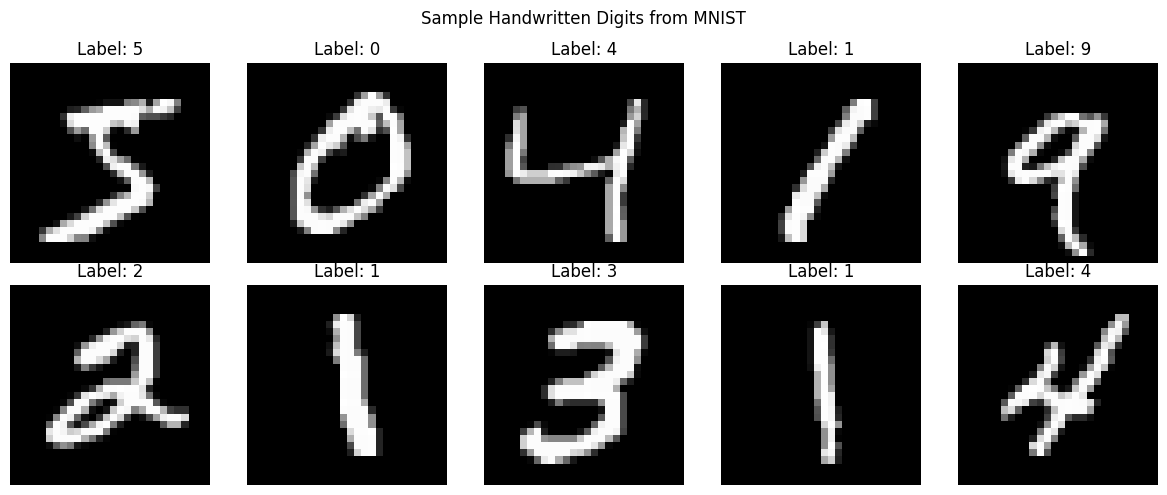

In [5]:

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Handwritten Digits from MNIST")
plt.tight_layout()
plt.show()

5. **Data Preprocessing**

The MNIST images contain pixel values ranging from 0 to 255. We normalize these values to the range 0 to 1 by dividing them by 255.

Next, we add a channel dimension to represent grayscale images in the format required by the CNN model. The labels remain unchanged because we are using sparse categorical cross-entropy during training.

In [6]:

# Normalize pixel values to the range 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add the channel dimension for CNN input
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Display the processed data information
print("Preprocessing completed successfully!")

print("\nTraining images shape:", X_train.shape)
print("Testing images shape:", X_test.shape)

print("\nPixel value range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Preprocessing completed successfully!

Training images shape: (60000, 28, 28, 1)
Testing images shape: (10000, 28, 28, 1)

Pixel value range:
Minimum: 0.0
Maximum: 1.0


6. **Building the Convolutional Neural Network (CNN)**

A Convolutional Neural Network (CNN) is a deep learning model well suited for image recognition.

The model consists of convolutional layers to extract image features, max-pooling layers to reduce spatial dimensions, a flatten layer to convert feature maps into a vector, and dense layers to classify the handwritten digits.

The output layer contains 10 neurons, representing the digits 0 to 9, with softmax activation to produce class probabilities.

In [7]:

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

7. **Compiling the CNN Model**

The model is compiled using the Adam optimizer and sparse categorical cross-entropy loss. Accuracy is used as the evaluation metric to monitor the model's performance during training.

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


8. **Training the CNN Model**

The CNN model is trained using the preprocessed MNIST training dataset. The model learns patterns and features from handwritten digit images over 5 epochs. A validation split of 10% is used to monitor its performance on unseen training samples.

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("\nModel training completed successfully!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.9207 - loss: 0.2627 - val_accuracy: 0.9790 - val_loss: 0.0659
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9764 - loss: 0.0775 - val_accuracy: 0.9868 - val_loss: 0.0476
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9834 - loss: 0.0560 - val_accuracy: 0.9877 - val_loss: 0.0432
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9873 - loss: 0.0431 - val_accuracy: 0.9905 - val_loss: 0.0352
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9889 - loss: 0.0355 - val_accuracy: 0.9902 - val_loss: 0.0322

Model training completed successfully!


9. **Evaluating the CNN Model**

The trained CNN model is evaluated using the MNIST test dataset, which was not used during training. Test loss and test accuracy are calculated to measure the model's performance on unseen handwritten digit images.

In [10]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9905 - loss: 0.0277

Test Loss: 0.0277
Test Accuracy: 99.05 %


10. **Visualizing Actual and Predicted Digits**

The trained CNN model predicts digits from the MNIST test dataset. The predicted labels are compared with the actual labels to visually inspect the model's performance.

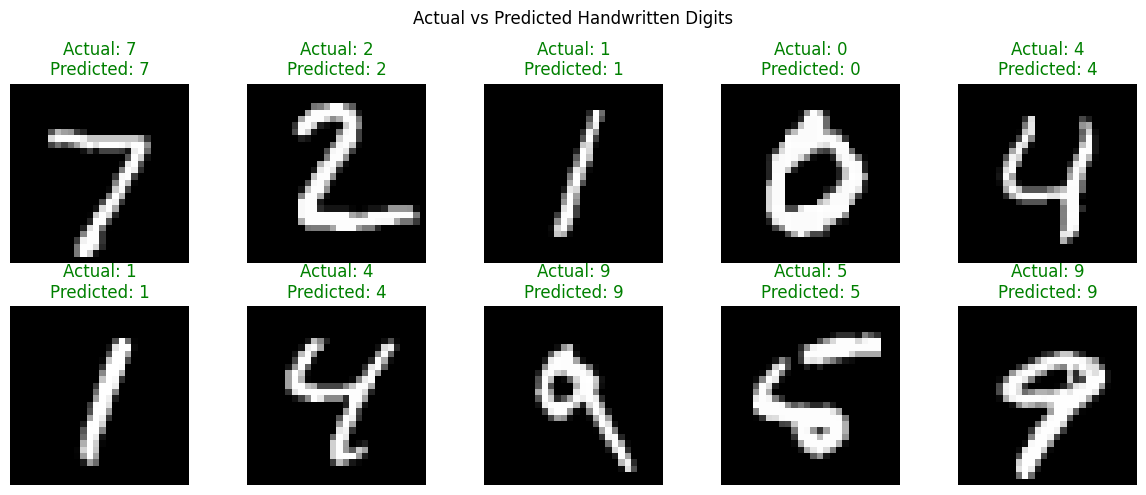

In [11]:
predictions = model.predict(X_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = predicted_labels[i]

    color = "green" if actual == predicted else "red"
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis("off")

plt.suptitle("Actual vs Predicted Handwritten Digits")
plt.tight_layout()
plt.show()

11. **Confusion Matrix and Classification Report**

A confusion matrix compares the actual and predicted digit classes. A classification report provides precision, recall, and F1-score for each digit from 0 to 9. These metrics help evaluate the performance of the trained CNN model in greater detail.

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       1.00      0.98      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



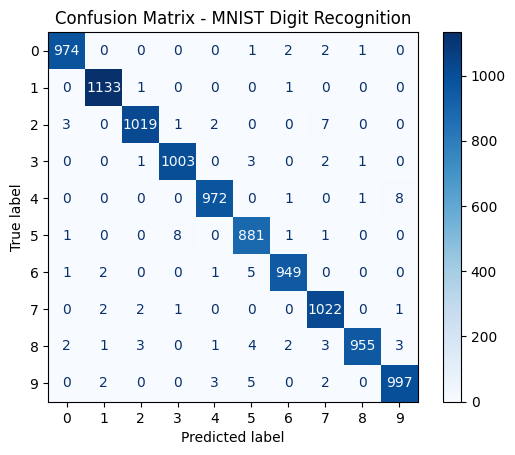

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

# Predict all test images
all_predictions = model.predict(X_test, verbose=0)
predicted_labels = np.argmax(all_predictions, axis=1)

# Generate classification report
print("Classification Report:\n")
print(classification_report(y_test, predicted_labels))

# Plot confusion matrix
cm = confusion_matrix(y_test, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - MNIST Digit Recognition")
plt.show()

12. **Visualizing Training and Validation Performance**

Training and validation accuracy and loss curves are plotted to analyze the learning behavior of the CNN model. These graphs help us understand how the model performs during training and identify possible overfitting.

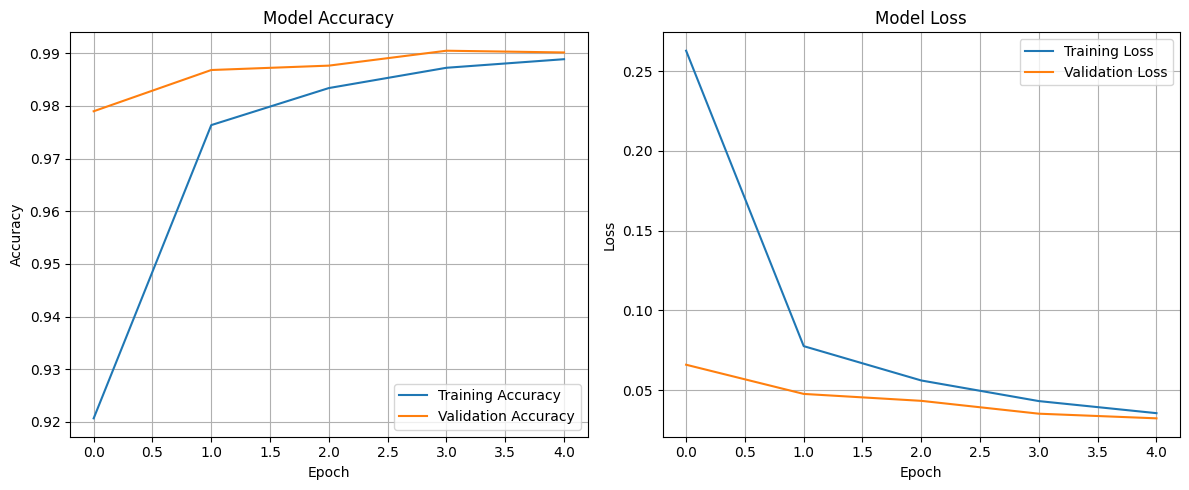

In [13]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

13. **Loading the EMNIST Dataset**

The EMNIST (Extended MNIST) dataset contains handwritten letters and digits. In this project, the EMNIST ByClass dataset will be used to prepare uppercase English letters (A–Z) for alphabet recognition using a Convolutional Neural Network (CNN).

In [17]:
%pip install -q importlib-resources

In [18]:
(train_ds, test_ds), info = tfds.load(
    "emnist/byclass",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)

print("EMNIST dataset loaded successfully!")

print("\nTraining examples:", info.splits["train"].num_examples)
print("Testing examples:", info.splits["test"].num_examples)
print("Total classes in original dataset:", info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/byclass/incomplete.J6PD9M_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/byclass/incomplete.J6PD9M_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/byclass/3.1.0. Subsequent calls will reuse this data.
EMNIST dataset loaded successfully!

Training examples: 697932
Testing examples: 116323
Total classes in original dataset: 62


14. **Filtering Uppercase English Letters**

The EMNIST ByClass dataset contains digits, uppercase letters, and lowercase letters. In this step, only uppercase letters A–Z are selected. Their original labels (10–35) are remapped to labels 0–25 for training the alphabet recognition model.

In [21]:

def is_uppercase(image, label):
    return (label >= 10) & (label <= 35)

def remap_label(image, label):
    # Correct EMNIST image orientation
    image = tf.transpose(image, perm=[1, 0, 2])

    # Remap labels: A=0, B=1, ..., Z=25
    label = label - 10

    return image, label

train_upper = train_ds.filter(is_uppercase).map(remap_label)
test_upper = test_ds.filter(is_uppercase).map(remap_label)

print("Uppercase filtering and orientation correction completed!")
print("Original labels: 10–35")
print("New labels: 0–25")
print("Number of target classes: 26")

Uppercase filtering and orientation correction completed!
Original labels: 10–35
New labels: 0–25
Number of target classes: 26


15. **Visualizing Sample Uppercase Letters**

A sample of images is displayed from the filtered EMNIST dataset. Each image is shown with its corresponding alphabet label to verify that the uppercase letters have been selected correctly before preprocessing and model training.

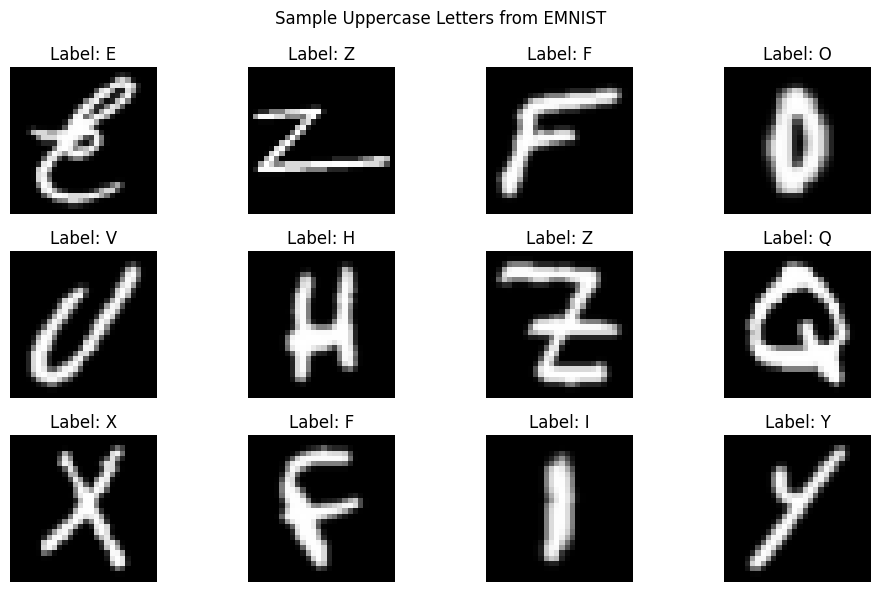

In [22]:
samples = list(train_upper.take(12).as_numpy_iterator())

plt.figure(figsize=(10, 6))

for i, (image, label) in enumerate(samples):
    plt.subplot(3, 4, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Label: {chr(int(label) + 65)}")
    plt.axis("off")

plt.suptitle("Sample Uppercase Letters from EMNIST")
plt.tight_layout()
plt.show()

16. **Preprocessing the EMNIST Dataset**

The selected uppercase letter images are converted to floating-point values and normalized to the range 0 to 1. The dataset is then shuffled, divided into batches, and prefetched to prepare it efficiently for CNN training.

In [23]:

def preprocess_image(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_data = (
    train_upper
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(10000)
    .batch(128)
    .prefetch(tf.data.AUTOTUNE)
)

test_data = (
    test_upper
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(128)
    .prefetch(tf.data.AUTOTUNE)
)

print("EMNIST preprocessing completed successfully!")
print("Image size: 28 x 28")
print("Pixel range: 0 to 1")
print("Number of classes: 26")
print("Batch size: 128")

EMNIST preprocessing completed successfully!
Image size: 28 x 28
Pixel range: 0 to 1
Number of classes: 26
Batch size: 128


17. **Building the CNN Model for Alphabet Recognition**

A Convolutional Neural Network (CNN) is developed to recognize 26 uppercase English letters. The model uses convolutional and max-pooling layers to extract image features, followed by dense layers for classification. The softmax output layer predicts one of the 26 classes, representing letters A–Z.

In [24]:
alphabet_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(26, activation="softmax")
])

alphabet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,098 (887.10 KB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)

18. **Compiling the Alphabet Recognition Model**

The alphabet recognition CNN model is compiled using the Adam optimizer and sparse categorical cross-entropy loss. Accuracy is selected as the evaluation metric to monitor the model's performance during training.

In [25]:
alphabet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Alphabet CNN model compiled successfully!")

Alphabet CNN model compiled successfully!


19. **Training the Alphabet Recognition Model**

The CNN model is trained on the preprocessed EMNIST uppercase letter dataset. During training, the model learns patterns and features from handwritten letters A–Z. A validation split is created from the training dataset to monitor the model's learning performance.

In [26]:
history_alphabet = alphabet_model.fit(
    train_data,
    epochs=5,
    validation_data=test_data,
    verbose=1
)

print("\nAlphabet model training completed successfully!")

Epoch 1/5
   1477/Unknown 73s 44ms/step - accuracy: 0.8184 - loss: 0.6479

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1477/1477 ━━━━━━━━━━━━━━━━━━━━ 85s 52ms/step - accuracy: 0.9060 - loss: 0.3355 - val_accuracy: 0.9649 - val_loss: 0.1224
Epoch 2/5
1477/1477 ━━━━━━━━━━━━━━━━━━━━ 129s 46ms/step - accuracy: 0.9588 - loss: 0.1483 - val_accuracy: 0.9703 - val_loss: 0.1015
Epoch 3/5
1477/1477 ━━━━━━━━━━━━━━━━━━━━ 73s 48ms/step - accuracy: 0.9669 - loss: 0.1205 - val_accuracy: 0.9758 - val_loss: 0.0831
Epoch 4/5
1477/1477 ━━━━━━━━━━━━━━━━━━━━ 71s 46ms/step - accuracy: 0.9714 - loss: 0.1044 - val_accuracy: 0.9772 - val_loss: 0.0802
Epoch 5/5
1477/1477 ━━━━━━━━━━━━━━━━━━━━ 73s 48ms/step - accuracy: 0.9745 - loss: 0.0920 - val_accuracy: 0.9791 - val_loss: 0.0741

Alphabet model training completed successfully!


20. **Evaluating the Alphabet Recognition Model**

The trained alphabet recognition CNN model is evaluated using the EMNIST test dataset. Test loss and accuracy are calculated to measure how well the model recognizes handwritten uppercase letters from A to Z.

In [27]:
alphabet_test_loss, alphabet_test_accuracy = alphabet_model.evaluate(
    test_data,
    verbose=1
)

print("\nAlphabet Model Evaluation Results")
print("Test Loss:", round(alphabet_test_loss, 4))
print("Test Accuracy:", round(alphabet_test_accuracy * 100, 2), "%")

245/245 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.9791 - loss: 0.0741

Alphabet Model Evaluation Results
Test Loss: 0.0741
Test Accuracy: 97.91 %


21. **Visualizing Actual and Predicted Alphabets**

The trained CNN model predicts uppercase letters from the EMNIST test dataset. Actual and predicted letters are displayed together to visually inspect the model's alphabet recognition performance.

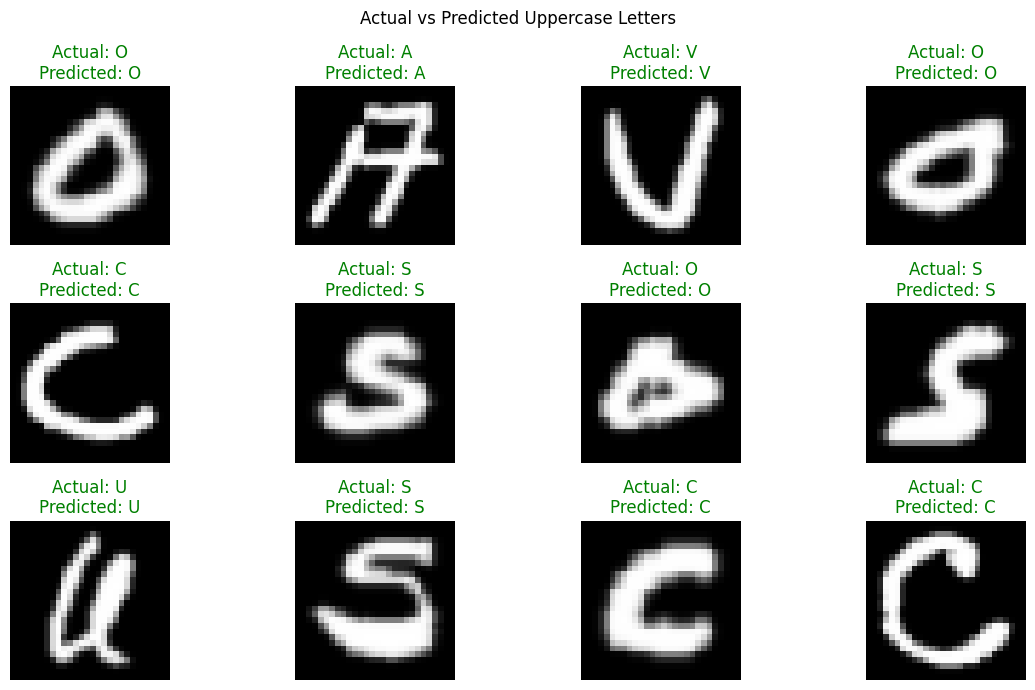

In [28]:
# Get a batch of test images
sample_images, sample_labels = next(iter(test_data))

# Select 12 images
sample_images = sample_images[:12]
sample_labels = sample_labels[:12]

# Predict the letters
probabilities = alphabet_model.predict(
    sample_images, verbose=0
)
predicted_labels = np.argmax(probabilities, axis=1)

# Display actual vs predicted letters
plt.figure(figsize=(12, 7))

for i in range(12):
    actual = int(sample_labels[i].numpy())
    predicted = int(predicted_labels[i])

    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().squeeze(), cmap="gray")

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {chr(actual + 65)}\nPredicted: {chr(predicted + 65)}",
        color=color
    )
    plt.axis("off")

plt.suptitle("Actual vs Predicted Uppercase Letters")
plt.tight_layout()
plt.show()

22. **Classification Report for Alphabet Recognition**

A classification report is generated to evaluate the alphabet recognition model for each uppercase letter from A to Z. It includes precision, recall, F1-score, and support to provide a detailed assessment of the model's performance across all 26 classes.

In [29]:
# Generate predictions for the entire test dataset
all_true_labels = []
all_predicted_labels = []

for images, labels in test_data:
    probabilities = alphabet_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    all_true_labels.extend(labels.numpy())
    all_predicted_labels.extend(predictions)

all_true_labels = np.array(all_true_labels)
all_predicted_labels = np.array(all_predicted_labels)

# Generate classification report
letter_names = [chr(i + 65) for i in range(26)]

print("Alphabet Classification Report:\n")

print(classification_report(
    all_true_labels,
    all_predicted_labels,
    labels=np.arange(26),
    target_names=letter_names,
    zero_division=0
))

Alphabet Classification Report:

              precision    recall  f1-score   support

           A       0.98      0.98      0.98      1062
           B       0.98      0.97      0.97       648
           C       0.98      0.99      0.98      1739
           D       0.95      0.90      0.93       779
           E       1.00      0.98      0.99       851
           F       0.98      0.98      0.98      1440
           G       0.98      0.97      0.97       447
           H       0.98      0.96      0.97       521
           I       0.99      0.99      0.99      2048
           J       0.96      0.95      0.95       626
           K       0.97      0.98      0.97       382
           L       0.97      0.98      0.98       810
           M       1.00      0.99      0.99      1485
           N       0.97      0.99      0.98      1351
           O       0.97      0.99      0.98      4156
           P       0.98      0.98      0.98      1397
           Q       0.98      0.96      0.97     

23. **Saving the Trained Alphabet Recognition Model**

The trained CNN model is saved in Keras format so that it can be loaded and reused later without retraining. This makes the alphabet recognition model easier to preserve and deploy in future applications.

In [30]:
alphabet_model.save("alphabet_recognition_model.keras")

print("Alphabet recognition model saved successfully!")

Alphabet recognition model saved successfully!


24. **Conclusion**

In this project, a Convolutional Neural Network (CNN) was developed for handwritten digit and uppercase alphabet recognition using the MNIST and EMNIST datasets.

The MNIST model achieved a test accuracy of approximately 99.05%, while the uppercase alphabet recognition model achieved a test accuracy of 97.91%.

The models were evaluated using test accuracy, loss, visual predictions, and classification reports. The results demonstrate that CNNs can effectively recognize handwritten digits and uppercase English letters from image data.

This project provided practical experience in image preprocessing, deep learning, model training, evaluation, and classification using TensorFlow and Keras.

25. **Final Project Verification**

The notebook is reviewed to ensure that the dataset preparation, CNN model training, evaluation results, visual predictions, classification reports, and project conclusion are included. The notebook is then saved for submission.

In [32]:
print("FINAL PROJECT CHECKLIST")
print("-----------------------")
print("MNIST digit recognition: Completed")
print("MNIST test accuracy: 99.05%")
print("EMNIST uppercase recognition: Completed")
print("Alphabet test accuracy: 97.91%")
print("Classification reports: Generated")
print("Visual predictions: Generated")
print("Project conclusion: Added")
print("\nNotebook verification checklist displayed.")

FINAL PROJECT CHECKLIST
-----------------------
MNIST digit recognition: Completed
MNIST test accuracy: 99.05%
EMNIST uppercase recognition: Completed
Alphabet test accuracy: 97.91%
Classification reports: Generated
Visual predictions: Generated
Project conclusion: Added

Notebook verification checklist displayed.
